# 1

In [14]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Audio, display


In [15]:
y, sr = librosa.load('data.wav', sr=None) # sr сохраняет исходную частоту



In [16]:
sr

44100

In [17]:
len(y) / sr

30.772244897959183

частоты дискритизации измеряется в гц - сколько раз в секунду измеряем колбеания в воздухе. Тут в файле 44кгц

Выбор частоты дискретизации в первую очередь определяет наивысшую частоту, которая может быть извлечена из сигнала. Это значение также, известно как предел Найквиста, и составляет ровно половину частоты дискретизации

Важно соблюдать при дообучении моедли одну и ту же частоту на которой обучалась модель исходная. Частота дисктритизации определяет временной интервал. Модели трансформеров, решающие аудиозадачи, рассматривают примеры как последовательности и полагаются на механизмы внимания для обучения аудио или мультимодальному представлению. Поскольку последовательности данных различны для аудиопримеров с разной частотой дискретизации, то моделям будет сложно обобщать данные для разных частот дискретизации

# 2. Спектограмма

In [18]:
display(Audio(y, rate=sr))


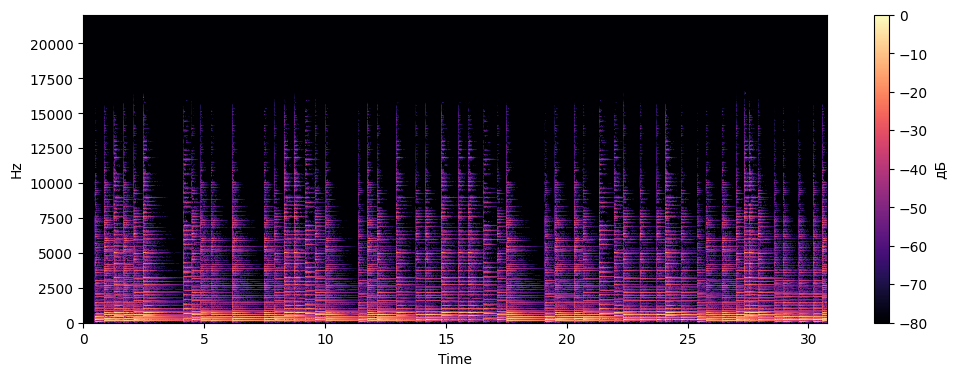

In [19]:


D = librosa.stft(y)






S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max) # ref=np.max задаёт за точку отсчёта максимум спектрограммы. поэтому все гб отрицательны

plt.figure(figsize=(12, 4))
librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz")
plt.colorbar(label="дБ")
plt.savefig("ne_mel.png", dpi=300, bbox_inches="tight")
plt.show()

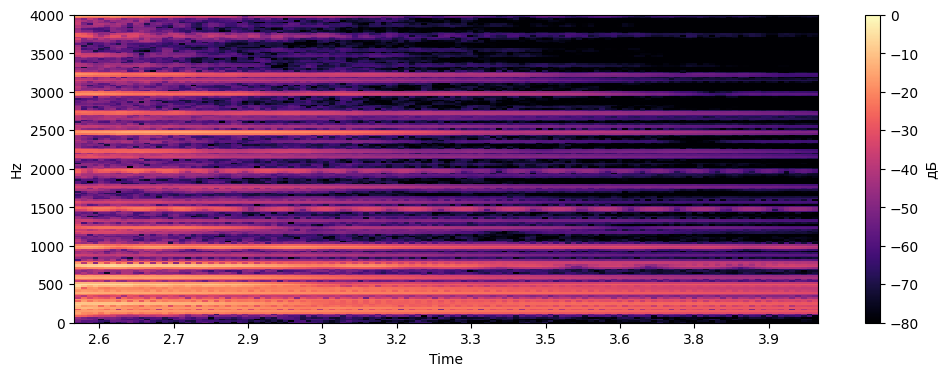

In [25]:
plt.figure(figsize=(12, 4))
librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz")
plt.xlim(2.5, 4)
plt.ylim(0, 4000)
plt.colorbar(label="дБ")
plt.savefig("ne_mel_zoom.png", dpi=300, bbox_inches="tight")
plt.show()

На увеличенном участке спектрограммы видны тонкие горизонтальные полосы около 1000, 1250, 1500, 1750 и 2000 Гц. Шаг между ними составляет примерно 250 Гц, поэтому их можно интерпретировать как гармоники звука с основной частотой около 250 Гц. Горизонтальное положение полос показывает, что частоты этих составляющих почти не меняются на выбранном участке

Спектрограмма представляет собой график изменения частотного содержания звукового сигнала во времени. Она позволяет увидеть время, частоту, и амплитуду на одном графике

Спектрограмма создается путем выделения коротких сегментов аудиосигнала, как правило, длительностью несколько миллисекунд, и вычисления дискретного преобразования Фурье каждого сегмента для получения его частотного спектра. 

Полученные спектры складываются вместе по оси времени для получения спектрограммы. По умолчанию librosa.stft() разбивает аудиосигнал на сегменты по 2048 выборок. Допустим есть резкий желчок и 2 близкий тона. с окротким окном можно более точно опредлеить оммент щелчка, но тогда различия между близкими тонами не накопятся. Емли взять больше окно, то момент щелчка менее точным будет зато лучше опрделим где разные тона

# 3. Mel-спектрограмма

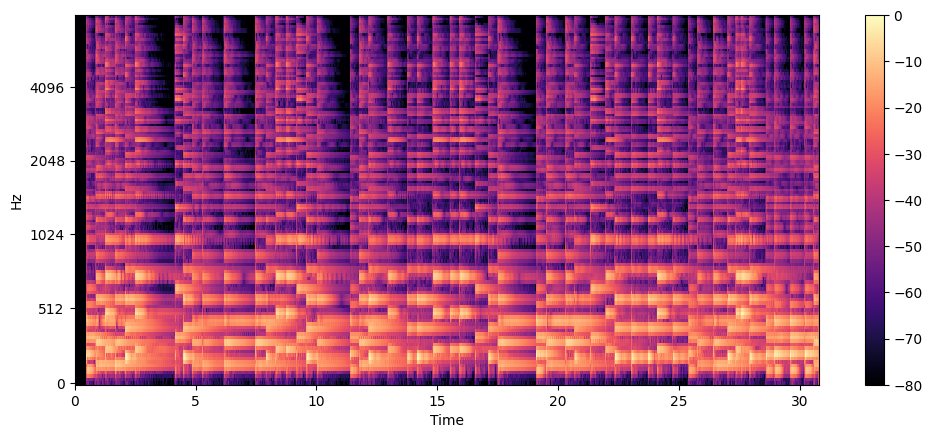

In [21]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sr, fmax=8000)
plt.colorbar()
plt.savefig('mel')

In [22]:
display(Audio(y, rate=sr))


В стандартной спектрограмме частотная ось линейна и измеряется в герцах (Гц). Однако слуховая система человека более чувствительна к изменениям на низких частотах, чем на высоких, и эта чувствительность уменьшается логарифмически с увеличением частоты. Шкала Мэл - это перцептивная (основанная на восприятии) шкала, которая аппроксимирует нелинейную частотную характеристику человеческого уха.

mel спектрограмма используется в распознавании речи для уменьшения числа параметров путем отбрасывания деталей для высоких частотах, тк человеческое ухо слабо там различает детали

# 4. Визуализация


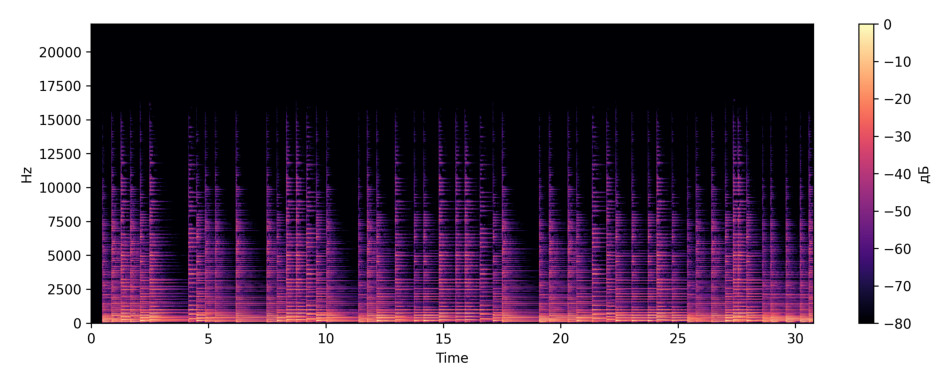

In [23]:
img = plt.imread('ne_mel.png')
plt.figure(figsize=(12, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

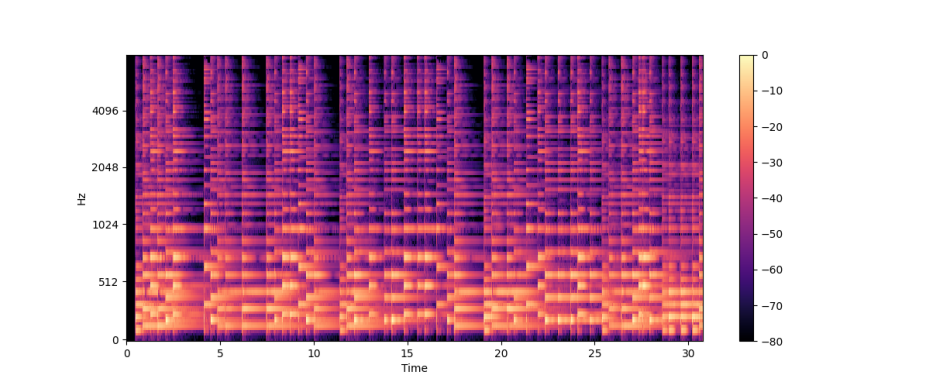

In [24]:
img = plt.imread('mel.png')
plt.figure(figsize=(12, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

# 5. Выводы

- Энергия: Интенсивность цвета показывает амплитуду или мощность частотной составляющей в каждый момент времени, измеряемую в децибелах (дБ). Светло-жёлтый, около 0 дБ - самый высокий уровень на график. Чем светлее - тем громче
- Грамоники: на увеличенной линейной спектрограмме видны тонкие горизонтальные полосы около 1000, 1250, 1500, 1750 и 2000 Гц. Шаг между ними составляет примерно 250 Гц, поэтому их можно интерпретировать как гармоники звука с основной частотой около 250 Гц. Горизонтальное положение полос показывает, что частоты этих составляющих почти не меняются на выбранном участке
- Паузы: Пауза выглядит как тёмная вертикальная полоса почти по всей высоте спектрограммы

# Доп. задание: сравните спектрограммы чистого сигнала и того же сигнала с добавленным шумом; постройте mel-спектрограмму с другим числом mel-фильтров и объясните разницу.


# 1. + Шум

In [27]:

rng = np.random.default_rng(42)
noise_level = 0.1 * np.sqrt(np.mean(y**2)) # Белый шум со среднеквадратичной амплитудой около 10% от амплитуды сигнала
y_noisy = y + rng.normal(0, noise_level, size=y.shape)


In [31]:
display(Audio(y_noisy, rate=sr))


In [29]:

# Спектрограммы зашумлённого сигнала с теми же параметрами
D_noisy = librosa.stft(y_noisy)
S_noisy = librosa.feature.melspectrogram(
    y=y_noisy, sr=sr, n_mels=128, fmax=8000
)

# Общая точка отсчёта для каждой пары, чтобы цвета можно было сравнивать
ref_linear = max(np.abs(D).max(), np.abs(D_noisy).max())
ref_mel = max(S.max(), S_noisy.max())


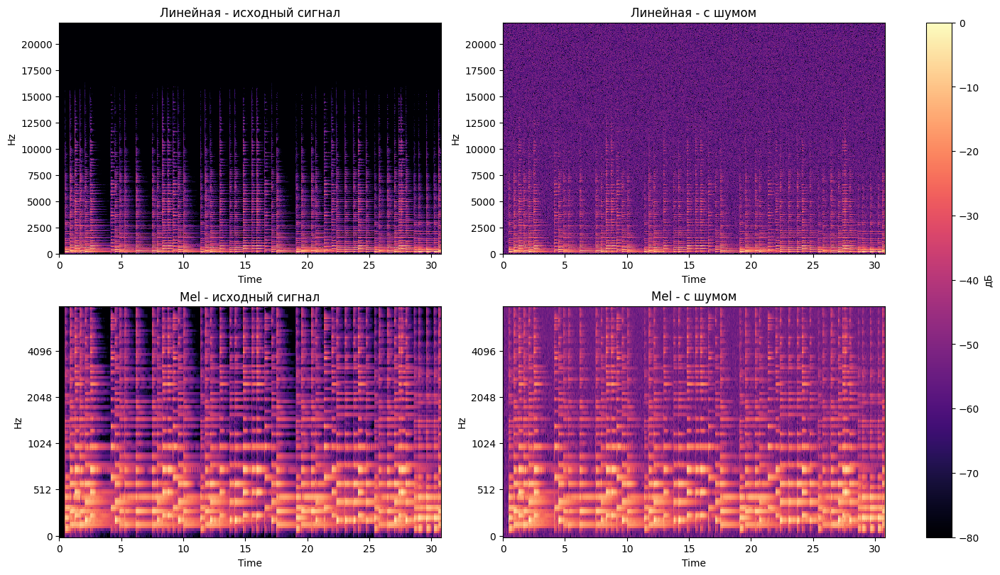

In [32]:

fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout="constrained")

for ax, spectrum, axis_type, title in [
    (axes[0, 0], librosa.amplitude_to_db(np.abs(D), ref=ref_linear),
     "hz", "Линейная - исходный сигнал"),
    (axes[0, 1], librosa.amplitude_to_db(np.abs(D_noisy), ref=ref_linear),
     "hz", "Линейная - с шумом"),
    (axes[1, 0], librosa.power_to_db(S, ref=ref_mel),
     "mel", "Mel - исходный сигнал"),
    (axes[1, 1], librosa.power_to_db(S_noisy, ref=ref_mel),
     "mel", "Mel - с шумом"),
]:
    img = librosa.display.specshow(
        spectrum, sr=sr, x_axis="time", y_axis=axis_type,
        fmax=8000, vmin=-80, vmax=0, ax=ax
    )
    ax.set_title(title)

fig.colorbar(img, ax=axes, label="дБ")
fig.savefig("noise_comparison.png", dpi=200)
plt.show()

In [35]:
y, sr = librosa.load('data.wav', sr=None) # sr сохраняет исходную частоту
display(Audio(y * 0.1, rate=sr))



с шумом спектрограмма стала грязнее. Практичесик нет темных обалстей. При этом старый силуэты все еще видны

# 2. Постройте mel-спектрограмму с другим числом mel-фильтров и
объясните разницу.


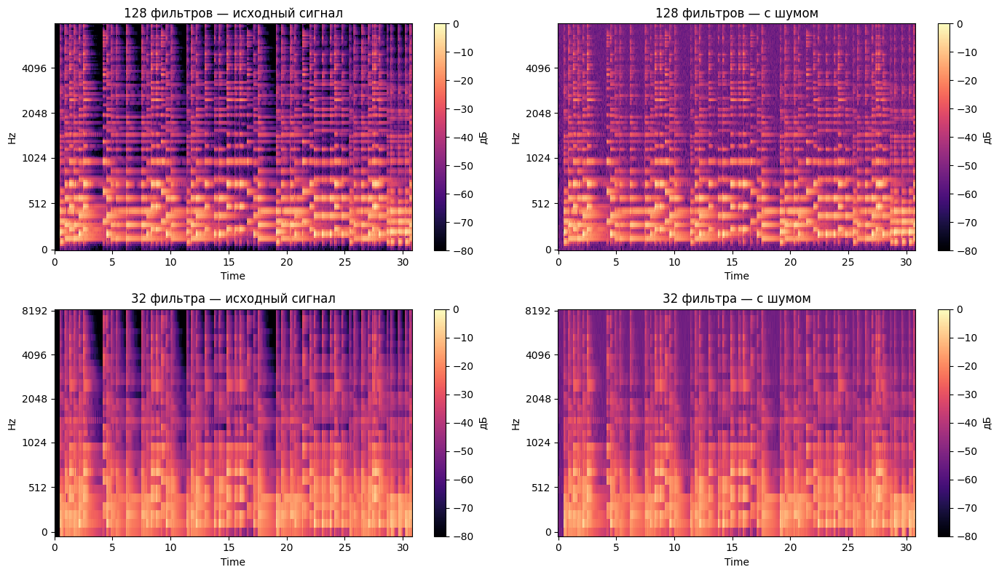

In [ ]:
S128 = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
S128_noise = librosa.feature.melspectrogram(y=y_noisy, sr=sr, n_mels=128, fmax=8000)
S32 = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=32, fmax=8000)
S32_noise = librosa.feature.melspectrogram(y=y_noisy, sr=sr, n_mels=32, fmax=8000)

ref = max(S128.max(), S128_noise.max(), S32.max(), S32_noise.max())

plt.figure(figsize=(14, 8))

for i, (S_mel, title) in enumerate([
    (S128, "128 фильтров — исходный сигнал"),
    (S128_noise, "128 фильтров — с шумом"),
    (S32, "32 фильтра — исходный сигнал"),
    (S32_noise, "32 фильтра — с шумом"),
], start=1):
    plt.subplot(2, 2, i)
    S_db = librosa.power_to_db(S_mel, ref=ref)
    librosa.display.specshow(
        S_db, sr=sr, x_axis="time", y_axis="mel",
        fmax=8000, vmin=-80, vmax=0
    )
    plt.title(title)
    plt.colorbar(label="дБ")

plt.tight_layout()
plt.show()

128 фильтров дают более подробную картину по частоте, а 32 фильтра дают более компактное представление. n_mels - это сколько mel-фильтров построить